# 06 - Final Model Evaluation

## 1. Objective

Notebook 05 selected **XGBoost** (400 rounds, `max_depth=2`, `learning_rate=0.05`) using the 2023 validation year. This notebook gives the **final, unbiased score** of that model:

1. Train the selected model on **all** historical training data (target weeks 2007-2023).
2. Predict next week's cases for the **test set** (target weeks 2024-2026). The test set has not been used in any earlier step.
3. Compare **MAE** and **RMSE** with the persistence baseline.
4. Save the trained model.

**Why the test set matters:** in notebooks 04 and 05 the model settings were chosen by looking at the 2023 scores, so those scores are slightly optimistic. The test weeks played no part in any decision, so the score on them shows how the model would perform on new data. The test set is used **once**, and no settings are changed afterwards.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

TRAIN_PATH = Path("../dataset/processed/train.csv")
TEST_PATH = Path("../dataset/processed/test.csv")
CONFIG_PATH = Path("../models/05_selected_model.json")
MODEL_PATH = Path("../models/06_final_xgboost_model.json")

# chart colours (the same as notebooks 04 and 05)
COLORS = {"Persistence": "#898781", "XGBoost": "#1baf7a"}
INK, GRID = "#0b0b0b", "#e4e3df"

## 2. Load the selected model settings

The settings, features and random seed are read from the file saved in notebook 05, so exactly the same model is rebuilt.

In [2]:
config = json.loads(CONFIG_PATH.read_text())

assert config["selected_model"] == "XGBoost"
FEATURES = config["features"]
TARGET = config["target"]
PARAMS = config["params"]
RANDOM_STATE = config["random_state"]

print("model:", config["selected_model"])
print("settings:", PARAMS)
print("features:", len(FEATURES), "| target:", TARGET)

model: XGBoost
settings: {'n_estimators': 400, 'max_depth': 2, 'learning_rate': 0.05}
features: 11 | target: cases_next


## 3. Load the training and test data

- `train.csv`: target weeks 2007-2023, the historical data used to fit the model.
- `test.csv`: target weeks 2024-2026, used only for this final evaluation.

**Leakage check (same as notebooks 04 and 05):** rows with an interpolated current week (`is_imputed`) are removed, because their value was calculated from next week's cases, i.e. from the target. Rows with an interpolated target (`target_imputed`) are removed too, because that target is an estimate, not a real observation. In the test set this affects a few weeks in 2026 that were repaired in notebook 02.

In [3]:
train = pd.read_csv(TRAIN_PATH, parse_dates=["start_date", "target_date"])
test = pd.read_csv(TEST_PATH, parse_dates=["start_date", "target_date"])

# leakage check: interpolated weeks
train_leaky = train["is_imputed"] | train["target_imputed"]
test_leaky = test["is_imputed"] | test["target_imputed"]
train = train[~train_leaky].reset_index(drop=True)
test = test[~test_leaky].reset_index(drop=True)
print("removed interpolated rows: train", train_leaky.sum(), "| test", test_leaky.sum())

# safety checks: training weeks all come before test weeks, no missing values, target not an input
assert train["target_date"].max() < test["target_date"].min()
assert train[FEATURES + [TARGET]].notna().all().all() and test[FEATURES + [TARGET]].notna().all().all()
assert TARGET not in FEATURES

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

print("training rows:", len(train), "| target weeks", train["target_date"].min().date(), "to", train["target_date"].max().date())
print("test rows:    ", len(test), "| target weeks", test["target_date"].min().date(), "to", test["target_date"].max().date())

removed interpolated rows: train 52 | test 106
training rows: 21684 | target weeks 2007-12-29 to 2023-12-30
test rows:     3508 | target weeks 2024-01-06 to 2026-08-29


## 4. Train the final model

In notebook 05 the model was trained on 2007-2022, because 2023 was held back for validation. Now that the settings are fixed, 2023 is no longer needed for choosing anything. The final model is therefore trained on **all** training years (2007-2023), so it also learns from the most recent data.

In [4]:
final_model = XGBRegressor(**PARAMS, random_state=RANDOM_STATE, n_jobs=-1)
final_model.fit(X_train, y_train)

train_mae = mean_absolute_error(y_train, np.clip(final_model.predict(X_train), 0, None))
print("trained on", len(X_train), "rows | training MAE:", round(train_mae, 2))

trained on 21684 rows | training MAE: 10.31


## 5. Predict the test weeks

- **XGBoost:** the model's prediction, clipped at 0 because case counts cannot be negative.
- **Persistence baseline:** next week = this week (`current_week_cases`).

In [5]:
xgb_pred = np.clip(final_model.predict(X_test), 0, None)
persistence_pred = test["current_week_cases"].to_numpy()

def evaluate(actual, predicted):
    return {"MAE": mean_absolute_error(actual, predicted), "RMSE": root_mean_squared_error(actual, predicted)}

## 6. Test results

MAE and RMSE are in cases per district-week. Lower is better. The last two columns show the change compared with persistence (negative = better than persistence).

In [6]:
test_results = pd.DataFrame({
    "Persistence": evaluate(y_test, persistence_pred),
    "XGBoost": evaluate(y_test, xgb_pred),
}).T

test_results["MAE vs persistence (%)"] = 100 * (test_results["MAE"] / test_results.loc["Persistence", "MAE"] - 1)
test_results["RMSE vs persistence (%)"] = 100 * (test_results["RMSE"] / test_results.loc["Persistence", "RMSE"] - 1)
test_results.round(2)

,MAE,RMSE,MAE vs persistence (%),RMSE vs persistence (%)
Persistence,12.63,29.93,0.00,0.00
XGBoost,13.22,39.19,4.63,30.94


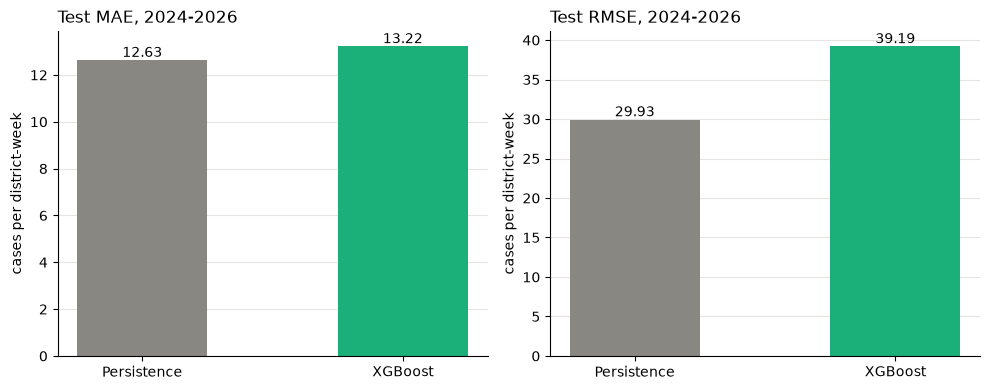

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    values = test_results[metric].to_numpy()
    ax.bar(test_results.index, values, color=[COLORS[name] for name in test_results.index], width=0.5)
    for i, v in enumerate(values):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom")
    ax.set_title(f"Test {metric}, 2024-2026", loc="left")
    ax.set_ylabel("cases per district-week")
    ax.grid(axis="y", color=GRID)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Validation (2023) vs test (2024-2026)

The validation scores from notebook 05 next to the test scores. The test period had much larger dengue outbreaks than 2023, so **all errors are larger in cases**. The fair comparison is the **change vs persistence** in each period.

In [8]:
valid_scores = config["validation_scores"]
period_comparison = pd.DataFrame({
    "validation MAE (2023)": [valid_scores["Persistence"]["MAE"], valid_scores["XGBoost"]["MAE"]],
    "validation RMSE (2023)": [valid_scores["Persistence"]["RMSE"], valid_scores["XGBoost"]["RMSE"]],
    "test MAE (2024-26)": test_results["MAE"].to_numpy(),
    "test RMSE (2024-26)": test_results["RMSE"].to_numpy(),
}, index=["Persistence", "XGBoost"])
period_comparison.round(2)

,validation MAE (2023),validation RMSE (2023),test MAE (2024-26),test RMSE (2024-26)
Persistence,18.17,41.82,12.63,29.93
XGBoost,18.10,41.34,13.22,39.19


### Results by test year

The test period covers three years. 2026 only runs until the end of August.

In [9]:
test_year = test["target_date"].dt.year
year_rows = []
for year in sorted(test_year.unique()):
    rows = (test_year == year).to_numpy()
    persistence_scores = evaluate(y_test[rows], persistence_pred[rows])
    xgb_scores = evaluate(y_test[rows], xgb_pred[rows])
    year_rows.append({
        "year": year,
        "rows": rows.sum(),
        "mean weekly cases": y_test[rows].mean(),
        "Persistence MAE": persistence_scores["MAE"],
        "XGBoost MAE": xgb_scores["MAE"],
        "Persistence RMSE": persistence_scores["RMSE"],
        "XGBoost RMSE": xgb_scores["RMSE"],
    })

by_year = pd.DataFrame(year_rows).set_index("year")
by_year["MAE vs persistence (%)"] = 100 * (by_year["XGBoost MAE"] / by_year["Persistence MAE"] - 1)
by_year.round(2)

,rows,mean weekly cases,Persistence MAE,XGBoost MAE,Persistence RMSE,XGBoost RMSE,MAE vs persistence (%)
year,,,,,,,
2024,1352,37.14,10.45,9.47,21.15,20.62,-9.39
2025,1352,37.57,8.68,8.27,15.20,14.77,-4.74
2026,804,98.86,22.93,27.82,52.61,74.97,21.36


### Actual vs predicted: Colombo, 2024-2026

The district with the most cases, over the whole test period.

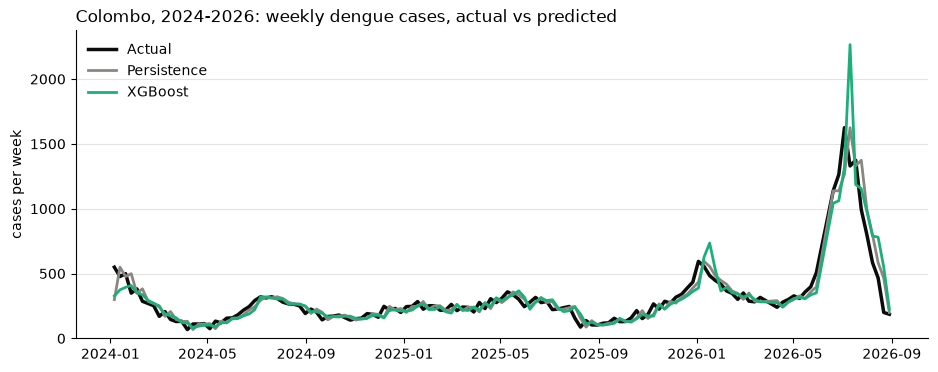

,Persistence,XGBoost
Colombo MAE 2024-26,49.43,58.12


In [10]:
colombo_rows = (test["district"] == "Colombo").to_numpy()
colombo_dates = test.loc[colombo_rows, "target_date"]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(colombo_dates, y_test[colombo_rows], color=INK, linewidth=2.5, label="Actual")
ax.plot(colombo_dates, persistence_pred[colombo_rows], color=COLORS["Persistence"], linewidth=2, label="Persistence")
ax.plot(colombo_dates, xgb_pred[colombo_rows], color=COLORS["XGBoost"], linewidth=2, label="XGBoost")
ax.set_title("Colombo, 2024-2026: weekly dengue cases, actual vs predicted", loc="left")
ax.set_ylabel("cases per week")
ax.set_ylim(bottom=0)
ax.grid(axis="y", color=GRID)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

pd.DataFrame({
    "Persistence": [mean_absolute_error(y_test[colombo_rows], persistence_pred[colombo_rows])],
    "XGBoost": [mean_absolute_error(y_test[colombo_rows], xgb_pred[colombo_rows])],
}, index=["Colombo MAE 2024-26"]).round(2)

### Where do the large errors come from?

RMSE punishes large misses, and XGBoost's test RMSE is much higher than persistence's. The table looks at the **very high weeks**: district-weeks where the current week already has more than 500 cases (outbreak peaks in the largest districts).

*Mean error* = average of (predicted - actual). A positive value means the model predicts **too many** cases.

In [11]:
high = (test["current_week_cases"] > 500).to_numpy()
xgb_sq_error = (xgb_pred - y_test) ** 2

pd.DataFrame({
    "district-weeks": [high.sum(), (~high).sum()],
    "Persistence MAE": [mean_absolute_error(y_test[high], persistence_pred[high]), mean_absolute_error(y_test[~high], persistence_pred[~high])],
    "XGBoost MAE": [mean_absolute_error(y_test[high], xgb_pred[high]), mean_absolute_error(y_test[~high], xgb_pred[~high])],
    "Persistence mean error": [(persistence_pred - y_test)[high].mean(), (persistence_pred - y_test)[~high].mean()],
    "XGBoost mean error": [(xgb_pred - y_test)[high].mean(), (xgb_pred - y_test)[~high].mean()],
    "share of XGBoost squared error (%)": [100 * xgb_sq_error[high].sum() / xgb_sq_error.sum(), 100 * xgb_sq_error[~high].sum() / xgb_sq_error.sum()],
}, index=["current week > 500 cases", "all other weeks"]).round(1)

,district-weeks,Persistence MAE,XGBoost MAE,Persistence mean error,XGBoost mean error,share of XGBoost squared error (%)
current week > 500 cases,37,169.1,251.3,75.7,130.7,67.7
all other weeks,3471,11.0,10.7,0.6,0.8,32.3


**What the test results show**

- **Overall, XGBoost does not beat persistence on the test set.** MAE is 13.22 vs 12.63 (+4.6%) and RMSE is 39.19 vs 29.93 (+31%). On the 2023 validation year the two were tied (XGBoost -0.4% MAE). On new data the small advantage did not hold.
- **It depends on the year.** XGBoost **is better** than persistence in 2024 (-9.4% MAE) and 2025 (-4.7% MAE), both years with moderate dengue activity. It is clearly **worse in 2026** (+21% MAE), the year of a very large outbreak: average cases per district-week were about 99, compared with about 37 in 2024 and 2025.
- **The large errors come from outbreak peaks.** Only 37 district-weeks had more than 500 cases in the current week, but they make up about 68% of XGBoost's squared error. In these weeks XGBoost predicts on average about 131 cases **too many** (persistence: about 76). The clearest example is Colombo in July 2026: the current week had 1,625 cases, next week had 1,330, and XGBoost predicted about 2,265. In past outbreaks a very high, fast-rising count was usually followed by an even higher one, and the model applied that pattern to a peak that was about to turn down. (The same overshoot at the Colombo peak was already visible in 2023, notebook 05.)
- **In all other weeks XGBoost is slightly better** than persistence (MAE 10.7 vs 11.0). So it helps in normal weeks but can make very large mistakes at the top of an outbreak.
- **Data quality note:** the last few weeks of 2026 (mid- to late August) show a sharp national drop that may partly be incomplete reporting (see notebooks 02 and 03). These weeks are kept, because there is no reliable way to correct them, but they add some uncertainty to the 2026 scores.

## 7. Save the trained model

The model is saved in XGBoost's own JSON format with `save_model`. This format can be loaded again by any XGBoost version, for example in the dashboard.

To check that the file is correct, it is loaded back and must give exactly the same test predictions.

In [12]:
MODEL_PATH.parent.mkdir(exist_ok=True)
final_model.save_model(MODEL_PATH)

loaded_model = XGBRegressor()
loaded_model.load_model(MODEL_PATH)
assert np.allclose(np.clip(loaded_model.predict(X_test), 0, None), xgb_pred)

print("saved", MODEL_PATH, f"({MODEL_PATH.stat().st_size / 1024:.0f} KB)")
print("reloaded model gives identical predictions")

saved ..\models\06_final_xgboost_model.json (285 KB)
reloaded model gives identical predictions


**Using the saved model:** load it with `XGBRegressor().load_model(...)`, pass the 11 features in the same order (`FEATURES`), and clip the prediction at 0.

## 8. Summary

**Final test scores** (target weeks 2024-01-06 to 2026-08-29, 3,508 district-weeks; the model was trained on 2007-2023)

| Model | Test MAE | Test RMSE | MAE vs persistence | RMSE vs persistence |
|---|---|---|---|---|
| Persistence | 12.63 | 29.93 | - | - |
| XGBoost (400 rounds, depth 2, lr 0.05) | 13.22 | 39.19 | +4.6% | +31% |

| Year | Persistence MAE | XGBoost MAE | Change |
|---|---|---|---|
| 2024 | 10.45 | 9.47 | -9.4% |
| 2025 | 8.68 | 8.27 | -4.7% |
| 2026 (to August) | 22.93 | 27.82 | +21.4% |

**Conclusions**
1. On unseen data, the selected XGBoost model is **better than persistence in normal and moderate weeks** (2024, 2025, and all weeks below 500 cases), but **overall it does not beat persistence**. Large overestimates at the peak of the 2026 outbreak outweigh those gains.
2. This is why a separate test set is needed. The 2023 validation score suggested a small advantage, but on new years the result depends strongly on whether there is a large outbreak.
3. The model was evaluated **once** on the test set and nothing was changed afterwards, so these numbers are an honest estimate of its performance.

**Saved model:** `models/06_final_xgboost_model.json` (XGBoost format; load with `XGBRegressor().load_model(...)`, use the 11 features in the same order, and clip predictions at 0).

**Possible improvements (future work):** information that can signal a coming rise or fall, such as rainfall and temperature, and models that are more cautious at very high case counts. If a different model is chosen because of these test results, it would need a new, untouched test period to be evaluated fairly.